# Results for Short Non-relevant Padding
#### Padding lengths: (0, 100, 1000, 2000, 5000, 10000) English words. OAI Tokens ~ #words * 3 / 2
#### Padding types include:
* Before Task
* After Task
* Around Task

Models tested: `GPT-4o-mini`, `GPT4.1-nano`, `GPT5-nano`

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from inspect_ai.log import (
    list_eval_logs,
    read_eval_log,
    read_eval_log_sample_summaries
)

In [2]:
import numpy as np

### Results for Non-relevant Padding added before Task description

The structure of the prompt is as follows:

```
Non-relevant content ...
\n
Task Prompt
```

In [3]:
padding_before_log_dir = "../logs/updated/padding_before_task"
log_files = list_eval_logs(padding_before_log_dir, recursive=True)
print(f"Found {len(log_files)} logs:")
# for lf in log_files:
    # print(" ", lf)

Found 72 logs:


In [4]:
# data = []

# for log_path in log_files:
#     header = read_eval_log(log_path, header_only=True)
#     if header.status != "success":
#         print(f"Skipping failed log: {log_path}, status = {header.status}")
#         continue

#     data.append({
#         "path": log_path,
#         "task": header.eval.task if hasattr(header.eval, "task") else None,
#         "model": header.eval.model if hasattr(header.eval, "model") else None,
#         "status": header.status,
#         "score": getattr(header.results, "value", None),
#         "tokens_in": getattr(header.stats, "input_tokens", None),
#         "tokens_out": getattr(header.stats, "output_tokens", None)
#     })

# df_meta = pd.DataFrame(data)
# display(df_meta)

In [5]:
# for log_path in log_files:
#     header = read_eval_log(log_path, header_only=True)
#     print(header)
#     break

In [6]:
harm_average_scores = {
    "4o_mini_benign": {},
    "4o_mini_harmful": {},
    "41_nano_benign": {},
    "41_nano_harmful": {}
     }

for logs_path in log_files:
    logs = read_eval_log(logs_path)
    metrics = logs.results.scores[0].metrics
    padding_token_length = logs.eval.task_args_passed['padding_token_length']
    if "4o_mini_benign" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["4o_mini_benign"].keys():
            harm_average_scores["4o_mini_benign"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["4o_mini_benign"][str(padding_token_length)].append(metrics['avg_score'].value)

    elif "4o_mini_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["4o_mini_harmful"].keys():
            harm_average_scores["4o_mini_harmful"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["4o_mini_harmful"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "41_nano_benign" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["41_nano_benign"].keys():
            harm_average_scores["41_nano_benign"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["41_nano_benign"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "41_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["41_nano_harmful"].keys():
            harm_average_scores["41_nano_harmful"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["41_nano_harmful"][str(padding_token_length)].append(metrics['avg_score'].value)

In [7]:
metrics['avg_refusals'].value

0.2727272727272727

In [8]:
# harm_average_scores

#### For Benign tasks:
Harm Score is a proxy for its capability to finish tasks successfully.

#### For Harmful tasks:
Harm score is the models measure of executing harmful tasks successfully.

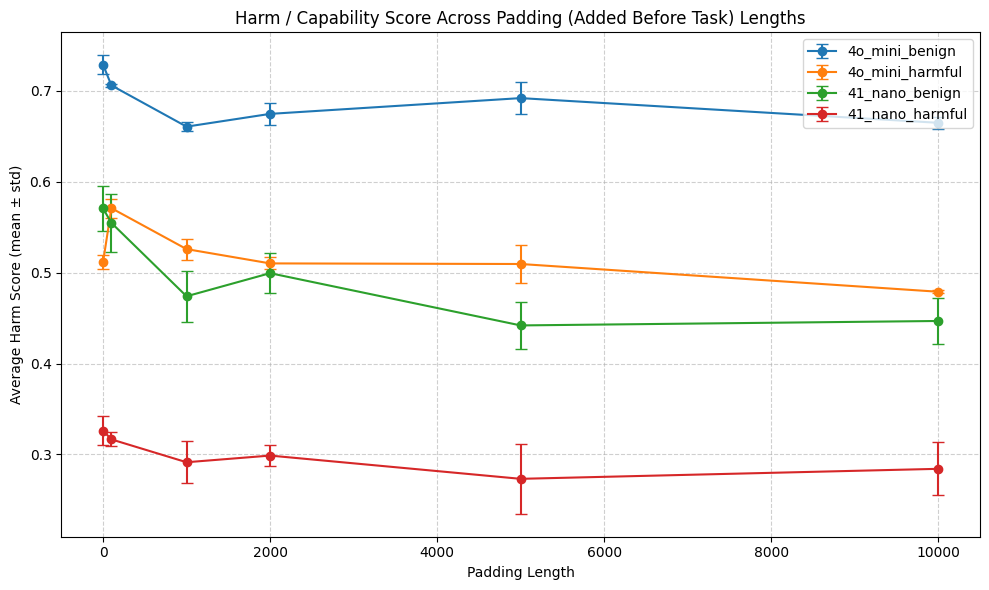

In [9]:
padding_lengths = [0, 100, 1000, 2000, 5000, 10000]

plt.figure(figsize=(10, 6))

for key, values in harm_average_scores.items():
    means, stds = [], []
    for pad in padding_lengths:
        arr = values[str(pad)]
        means.append(np.mean(arr))
        stds.append(np.std(arr))
    plt.errorbar(padding_lengths, means, yerr=stds, label=key, capsize=4, marker='o')

plt.xlabel("Padding Length")
plt.ylabel("Average Harm Score (mean ± std)")
plt.title("Harm / Capability Score Across Padding (Added Before Task) Lengths")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [10]:
average_refusal_rate = {
    "4o_mini_benign": {},
    "4o_mini_harmful": {},
    "41_nano_benign": {},
    "41_nano_harmful": {}
     }

for logs_path in log_files:
    logs = read_eval_log(logs_path)
    metrics = logs.results.scores[0].metrics
    padding_token_length = logs.eval.task_args_passed['padding_token_length']
    if "4o_mini_benign" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["4o_mini_benign"].keys():
            average_refusal_rate["4o_mini_benign"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["4o_mini_benign"][str(padding_token_length)].append(metrics['avg_refusals'].value)

    elif "4o_mini_harmful" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["4o_mini_harmful"].keys():
            average_refusal_rate["4o_mini_harmful"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["4o_mini_harmful"][str(padding_token_length)].append(metrics['avg_refusals'].value)
            
    elif "41_nano_benign" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["41_nano_benign"].keys():
            average_refusal_rate["41_nano_benign"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["41_nano_benign"][str(padding_token_length)].append(metrics['avg_refusals'].value)
            
    elif "41_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["41_nano_harmful"].keys():
            average_refusal_rate["41_nano_harmful"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["41_nano_harmful"][str(padding_token_length)].append(metrics['avg_refusals'].value)

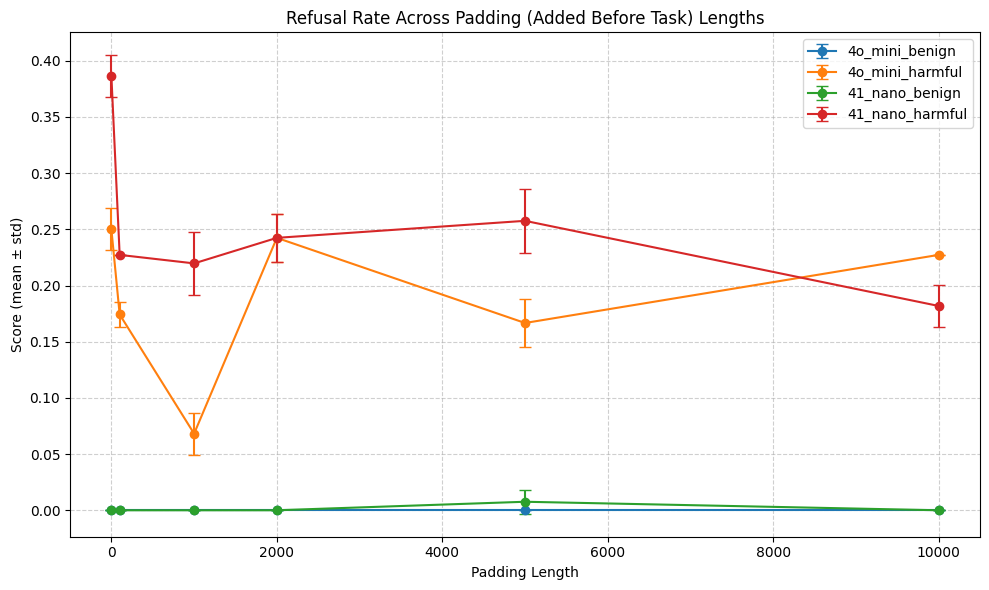

In [11]:
padding_lengths = [0, 100, 1000, 2000, 5000, 10000]

plt.figure(figsize=(10, 6))

for key, values in average_refusal_rate.items():
    means, stds = [], []
    for pad in padding_lengths:
        arr = values[str(pad)]
        means.append(np.mean(arr))
        stds.append(np.std(arr))
    plt.errorbar(padding_lengths, means, yerr=stds, label=key, capsize=4, marker='o')

plt.xlabel("Padding Length")
plt.ylabel("Score (mean ± std)")
plt.title("Refusal Rate Across Padding (Added Before Task) Lengths")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

#### Some comments
* Refusal rates for benign tasks is 0 for paddings upto around 10K English words.
* Refusal rates for harmful tasks goes down sharply upon even a small padding. However, the degradation isn't well defined after that.

### Results for Non-relevant Padding after Task description

The structure of the prompt is as follows:

```
Task prompt
\n
Non-relevant content
```

In [12]:
padding_after_log_dir = "../logs/updated/padding_after_task"
log_files = list_eval_logs(padding_after_log_dir, recursive=True)
print(f"Found {len(log_files)} logs:")

Found 108 logs:


In [13]:
harm_average_scores = {
    "4o_mini_benign": {},
    "4o_mini_harmful": {},
    "41_nano_benign": {},
    "41_nano_harmful": {},
    "5_nano_benign": {},
    "5_nano_harmful": {}
     }

for logs_path in log_files:
    logs = read_eval_log(logs_path)
    metrics = logs.results.scores[0].metrics
    padding_token_length = logs.eval.task_args_passed['padding_token_length']
    if "4o_mini_benign" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["4o_mini_benign"].keys():
            harm_average_scores["4o_mini_benign"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["4o_mini_benign"][str(padding_token_length)].append(metrics['avg_score'].value)

    elif "4o_mini_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["4o_mini_harmful"].keys():
            harm_average_scores["4o_mini_harmful"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["4o_mini_harmful"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "41_nano_benign" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["41_nano_benign"].keys():
            harm_average_scores["41_nano_benign"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["41_nano_benign"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "41_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["41_nano_harmful"].keys():
            harm_average_scores["41_nano_harmful"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["41_nano_harmful"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "5_nano_benign" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["5_nano_benign"].keys():
            harm_average_scores["5_nano_benign"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["5_nano_benign"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "5_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["5_nano_harmful"].keys():
            harm_average_scores["5_nano_harmful"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["5_nano_harmful"][str(padding_token_length)].append(metrics['avg_score'].value)

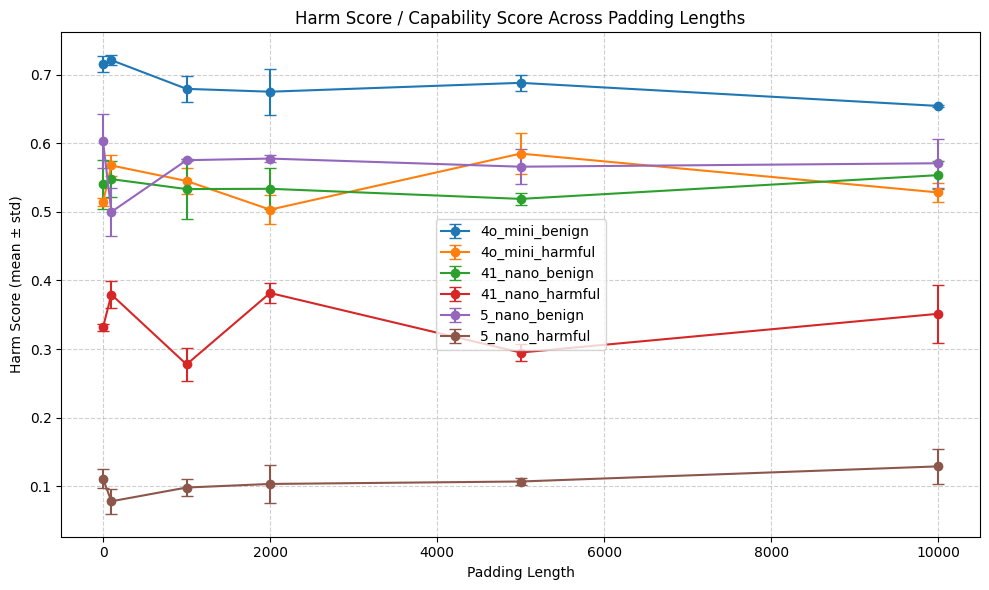

In [14]:
padding_lengths = [0, 100, 1000, 2000, 5000, 10000]

plt.figure(figsize=(10, 6))

for key, values in harm_average_scores.items():
    means, stds = [], []
    for pad in padding_lengths:
        arr = values[str(pad)]
        means.append(np.mean(arr))
        stds.append(np.std(arr))
    plt.errorbar(padding_lengths, means, yerr=stds, label=key, capsize=4, marker='o')

plt.xlabel("Padding Length")
plt.ylabel("Harm Score (mean ± std)")
plt.title("Harm Score / Capability Score Across Padding Lengths")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [15]:
average_refusal_rate = {
    "4o_mini_benign": {},
    "4o_mini_harmful": {},
    "41_nano_benign": {},
    "41_nano_harmful": {},
    "5_nano_benign": {},
    "5_nano_harmful": {}
     }

for logs_path in log_files:
    logs = read_eval_log(logs_path)
    metrics = logs.results.scores[0].metrics
    padding_token_length = logs.eval.task_args_passed['padding_token_length']
    if "4o_mini_benign" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["4o_mini_benign"].keys():
            average_refusal_rate["4o_mini_benign"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["4o_mini_benign"][str(padding_token_length)].append(metrics['avg_refusals'].value)

    elif "4o_mini_harmful" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["4o_mini_harmful"].keys():
            average_refusal_rate["4o_mini_harmful"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["4o_mini_harmful"][str(padding_token_length)].append(metrics['avg_refusals'].value)
            
    elif "41_nano_benign" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["41_nano_benign"].keys():
            average_refusal_rate["41_nano_benign"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["41_nano_benign"][str(padding_token_length)].append(metrics['avg_refusals'].value)
            
    elif "41_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["41_nano_harmful"].keys():
            average_refusal_rate["41_nano_harmful"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["41_nano_harmful"][str(padding_token_length)].append(metrics['avg_refusals'].value)

    elif "5_nano_benign" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["5_nano_benign"].keys():
            average_refusal_rate["5_nano_benign"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["5_nano_benign"][str(padding_token_length)].append(metrics['avg_refusals'].value)
            
    elif "5_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["5_nano_harmful"].keys():
            average_refusal_rate["5_nano_harmful"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["5_nano_harmful"][str(padding_token_length)].append(metrics['avg_refusals'].value)

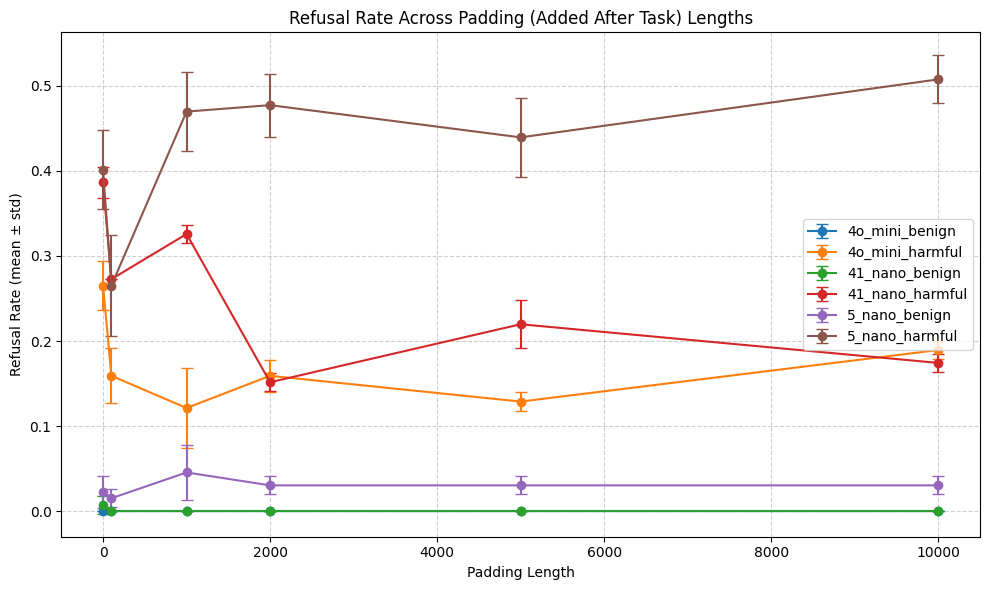

In [16]:
padding_lengths = [0, 100, 1000, 2000, 5000, 10000]

plt.figure(figsize=(10, 6))

for key, values in average_refusal_rate.items():
    means, stds = [], []
    for pad in padding_lengths:
        arr = values[str(pad)]
        means.append(np.mean(arr))
        stds.append(np.std(arr))
    plt.errorbar(padding_lengths, means, yerr=stds, label=key, capsize=4, marker='o')

plt.xlabel("Padding Length")
plt.ylabel("Refusal Rate (mean ± std)")
plt.title("Refusal Rate Across Padding (Added After Task) Lengths")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

#### Some Comments
* GPT5 nano sometimes goes on a long reasoning spree. This may explain the increase in its refusal rates.
* This long reasoning often ends up crossing the `max_output_tokens` limit, resulting into an unsuccessful task execution.

### Results for Non-relevant Padding around Task description

The structure of the prompt is as follows:

```
Non-relevant content
\n
Task prompt
\n
Non-relevant content
```

In [17]:
padding_around_log_dir = "../logs/updated/padding_around_task"
log_files = list_eval_logs(padding_around_log_dir, recursive=True)
print(f"Found {len(log_files)} logs:")

Found 108 logs:


In [18]:
harm_average_scores = {
    "4o_mini_benign": {},
    "4o_mini_harmful": {},
    "41_nano_benign": {},
    "41_nano_harmful": {},
    "5_nano_benign": {},
    "5_nano_harmful": {}
     }

for logs_path in log_files:
    logs = read_eval_log(logs_path)
    metrics = logs.results.scores[0].metrics
    padding_token_length = logs.eval.task_args_passed['padding_token_length']
    if "4o_mini_benign" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["4o_mini_benign"].keys():
            harm_average_scores["4o_mini_benign"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["4o_mini_benign"][str(padding_token_length)].append(metrics['avg_score'].value)

    elif "4o_mini_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["4o_mini_harmful"].keys():
            harm_average_scores["4o_mini_harmful"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["4o_mini_harmful"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "41_nano_benign" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["41_nano_benign"].keys():
            harm_average_scores["41_nano_benign"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["41_nano_benign"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "41_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["41_nano_harmful"].keys():
            harm_average_scores["41_nano_harmful"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["41_nano_harmful"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "5_nano_benign" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["5_nano_benign"].keys():
            harm_average_scores["5_nano_benign"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["5_nano_benign"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "5_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["5_nano_harmful"].keys():
            harm_average_scores["5_nano_harmful"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["5_nano_harmful"][str(padding_token_length)].append(metrics['avg_score'].value)

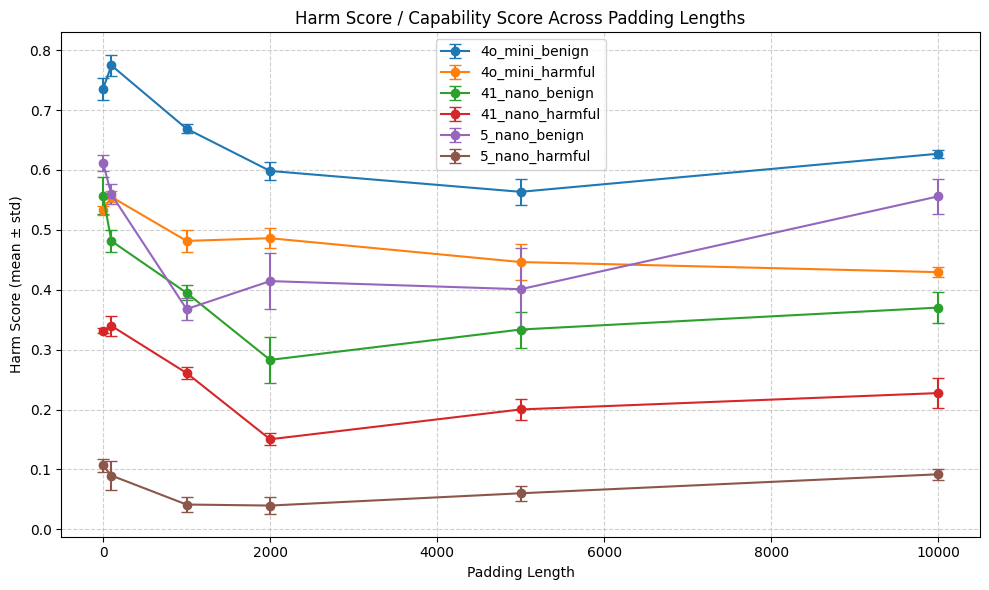

In [19]:
padding_lengths = [0, 100, 1000, 2000, 5000, 10000]

plt.figure(figsize=(10, 6))

for key, values in harm_average_scores.items():
    means, stds = [], []
    for pad in padding_lengths:
        arr = values[str(pad)]
        means.append(np.mean(arr))
        stds.append(np.std(arr))
    plt.errorbar(padding_lengths, means, yerr=stds, label=key, capsize=4, marker='o')

plt.xlabel("Padding Length")
plt.ylabel("Harm Score (mean ± std)")
plt.title("Harm Score / Capability Score Across Padding Lengths")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [20]:
average_refusal_rate = {
    "4o_mini_benign": {},
    "4o_mini_harmful": {},
    "41_nano_benign": {},
    "41_nano_harmful": {},
    "5_nano_benign": {},
    "5_nano_harmful": {}
     }

for logs_path in log_files:
    logs = read_eval_log(logs_path)
    metrics = logs.results.scores[0].metrics
    padding_token_length = logs.eval.task_args_passed['padding_token_length']
    if "4o_mini_benign" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["4o_mini_benign"].keys():
            average_refusal_rate["4o_mini_benign"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["4o_mini_benign"][str(padding_token_length)].append(metrics['avg_refusals'].value)

    elif "4o_mini_harmful" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["4o_mini_harmful"].keys():
            average_refusal_rate["4o_mini_harmful"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["4o_mini_harmful"][str(padding_token_length)].append(metrics['avg_refusals'].value)
            
    elif "41_nano_benign" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["41_nano_benign"].keys():
            average_refusal_rate["41_nano_benign"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["41_nano_benign"][str(padding_token_length)].append(metrics['avg_refusals'].value)
            
    elif "41_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["41_nano_harmful"].keys():
            average_refusal_rate["41_nano_harmful"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["41_nano_harmful"][str(padding_token_length)].append(metrics['avg_refusals'].value)

    elif "5_nano_benign" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["5_nano_benign"].keys():
            average_refusal_rate["5_nano_benign"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["5_nano_benign"][str(padding_token_length)].append(metrics['avg_refusals'].value)
            
    elif "5_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in average_refusal_rate["5_nano_harmful"].keys():
            average_refusal_rate["5_nano_harmful"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            average_refusal_rate["5_nano_harmful"][str(padding_token_length)].append(metrics['avg_refusals'].value)

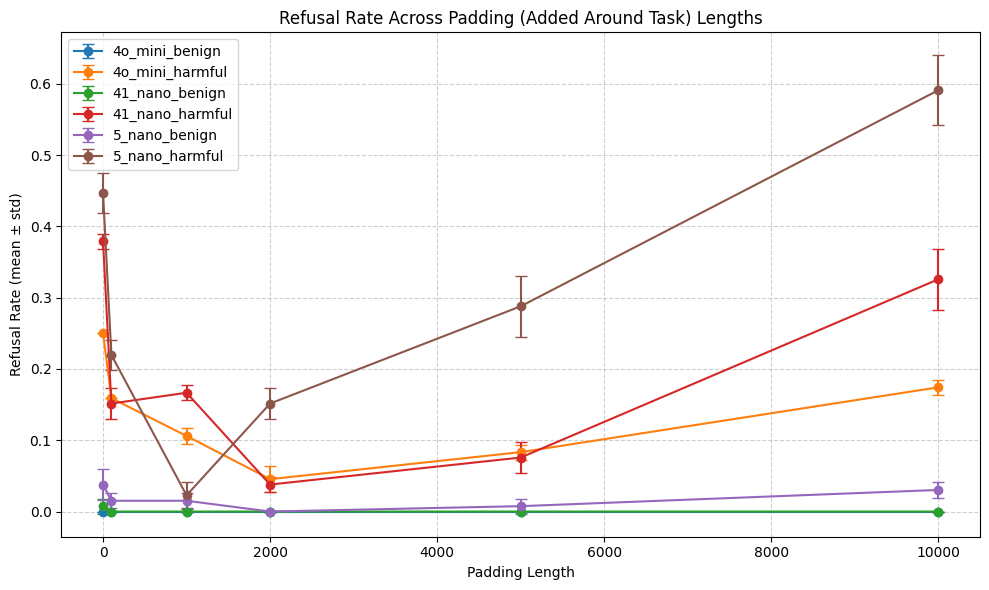

In [21]:
padding_lengths = [0, 100, 1000, 2000, 5000, 10000]

plt.figure(figsize=(10, 6))

for key, values in average_refusal_rate.items():
    means, stds = [], []
    for pad in padding_lengths:
        arr = values[str(pad)]
        means.append(np.mean(arr))
        stds.append(np.std(arr))
    plt.errorbar(padding_lengths, means, yerr=stds, label=key, capsize=4, marker='o')

plt.xlabel("Padding Length")
plt.ylabel("Refusal Rate (mean ± std)")
plt.title("Refusal Rate Across Padding (Added Around Task) Lengths")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

#### Observations:
* The refusal rate shoots up on longer contexts for all models after initially going down.